# AVALIAÇÃO 1 - Luiz Felipe Campos da Silva 22310854

*   Site utilizado: https://www.wimoveis.com.br
*   Contexto: Apartamentos para aluguel em Brasília.
*   Quantidade de imóveis raspados: 171


## Célula 1: Configurações e importação de bibliotecas

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")

## Célula 2: Limpeza, Remoção de Duplicatas e de Coluna Fixa

Conforme a célula abaixo mostrará, vários aspectos necessitaram atenção para limpar os dados:

1. A coluna de Tipo, inútil à análise, foi removida.
2. Ao buscar duplictas, 0 foram encontradas.
3. Alguns imóveis tiveram nomes de bairro corrompidos por botões do site. Portanto, criou-se uma classificação Outros/DF para tais.

Além disso, seguindo os requisitos da atividade, foram eliminados os valores ausentes utilizando dropna, foi criada a variável preco_m2, foram convertidos os valores numéricos, e os outliers - totalizando 4 - foram removidos.

In [22]:
# Carregamento dos dados brutos
df = pd.read_csv("apartamentos_brasilia.csv")
print(f"Total de registros: {len(df)}")

# Remoção da coluna redundante 'tipo'
if "tipo" in df.columns:
    df = df.drop(columns=["tipo"])

# Detecção e remoção de registros repetidos
duplicadas = df.duplicated(subset=["preco", "area_m2", "quartos", "vagas", "bairro"])
qtd_duplicadas = duplicadas.sum()
print(f"Linhas duplicadas: {qtd_duplicadas}")

# Tratamento dos nomes de bairros corrompidos por botões do site
bairros_invalidos = ["Contatar", "Agendar visita no QuintoAndar"]
df["bairro"] = df["bairro"].replace(bairros_invalidos, "Outro/DF")

# Tratamento de valores ausentes
df = df.dropna(subset=["preco", "area_m2"]).copy()

# Tratamento de tipos numéricos
df["preco"] = df["preco"].astype(str).str.replace(r"[^\d]", "", regex=True)
df["preco"] = pd.to_numeric(df["preco"], errors="coerce")

for col in ["area_m2", "quartos", "vagas"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Criação da variável preco_m2
df["preco_m2"] = df["preco"] / df["area_m2"]

# Remoção de Outliers via 3x IQR
q1 = df["preco"].quantile(0.25)
q3 = df["preco"].quantile(0.75)
iqr = q3 - q1
limite_inferior = max(0, q1 - 3 * iqr)
limite_superior = q3 + 3 * iqr

outliers = df[(df["preco"] < limite_inferior) | (df["preco"] > limite_superior)]
print(f"Outliers de preço (> 3*IQR): {len(outliers)}")

df_limpo = df[(df["preco"] >= limite_inferior) & (df["preco"] <= limite_superior)].copy()
print(f"Base final: {len(df_limpo)} imóveis.")



Total de registros: 171
Linhas duplicadas: 0
Outliers de preço (> 3*IQR): 4
Base final: 167 imóveis.


## Célula 3: Análise Exploratória de Dados

Fazenda a análise da Matriz de Correlação, é possível notar que a variável que mais afeta o preço é a metragem. A progressão é consideravelmente linear, mesmo que seja masi difícil de perceber após a faixa de 150m2. Outro ponto interessante de se notar é como o comportamento do gráfico de preço por quantidade de apartamentos englobados começa a apresentar a aparëncia de uma Curva Normal. Possivelmente, com mais dados, a curva se definiria mais.

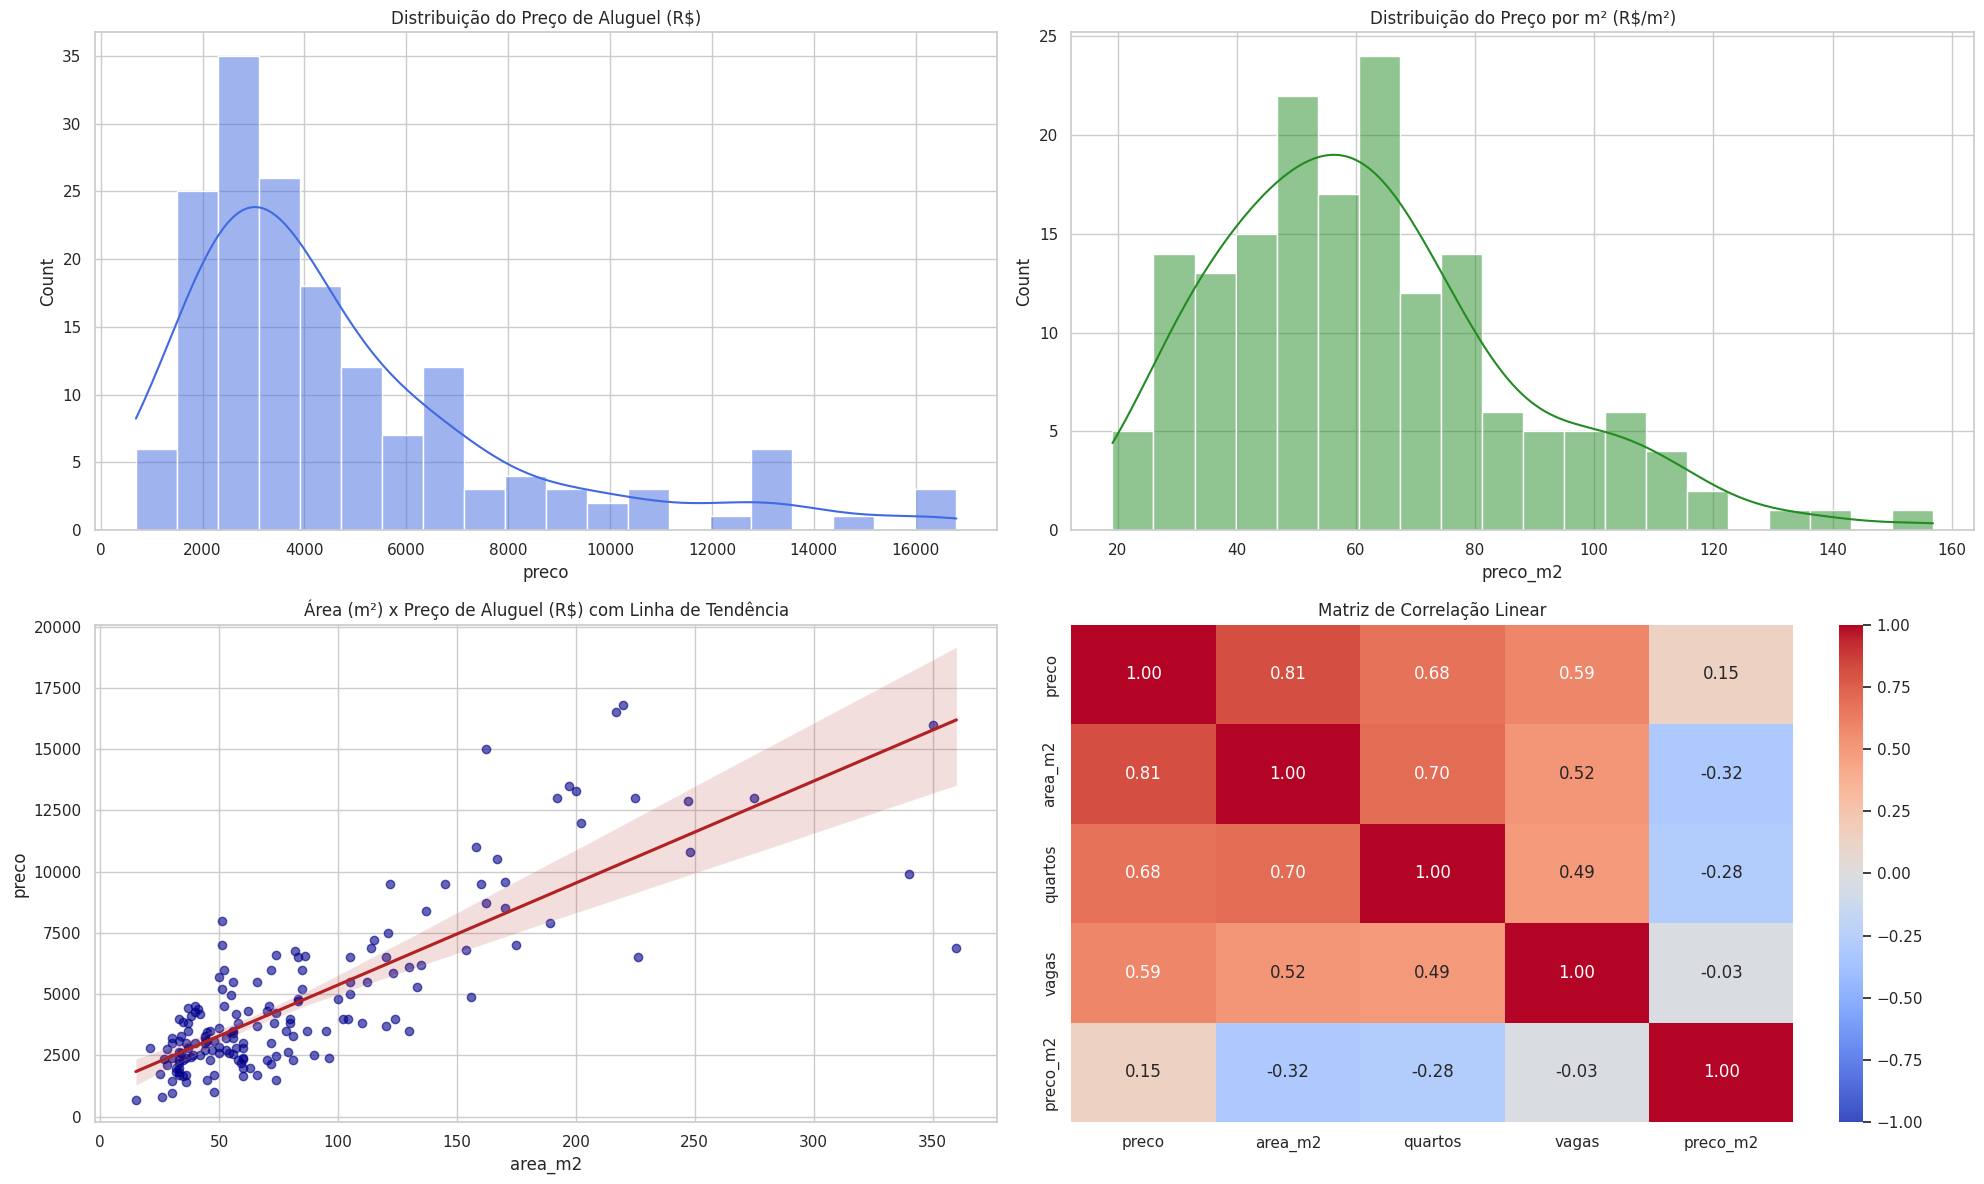

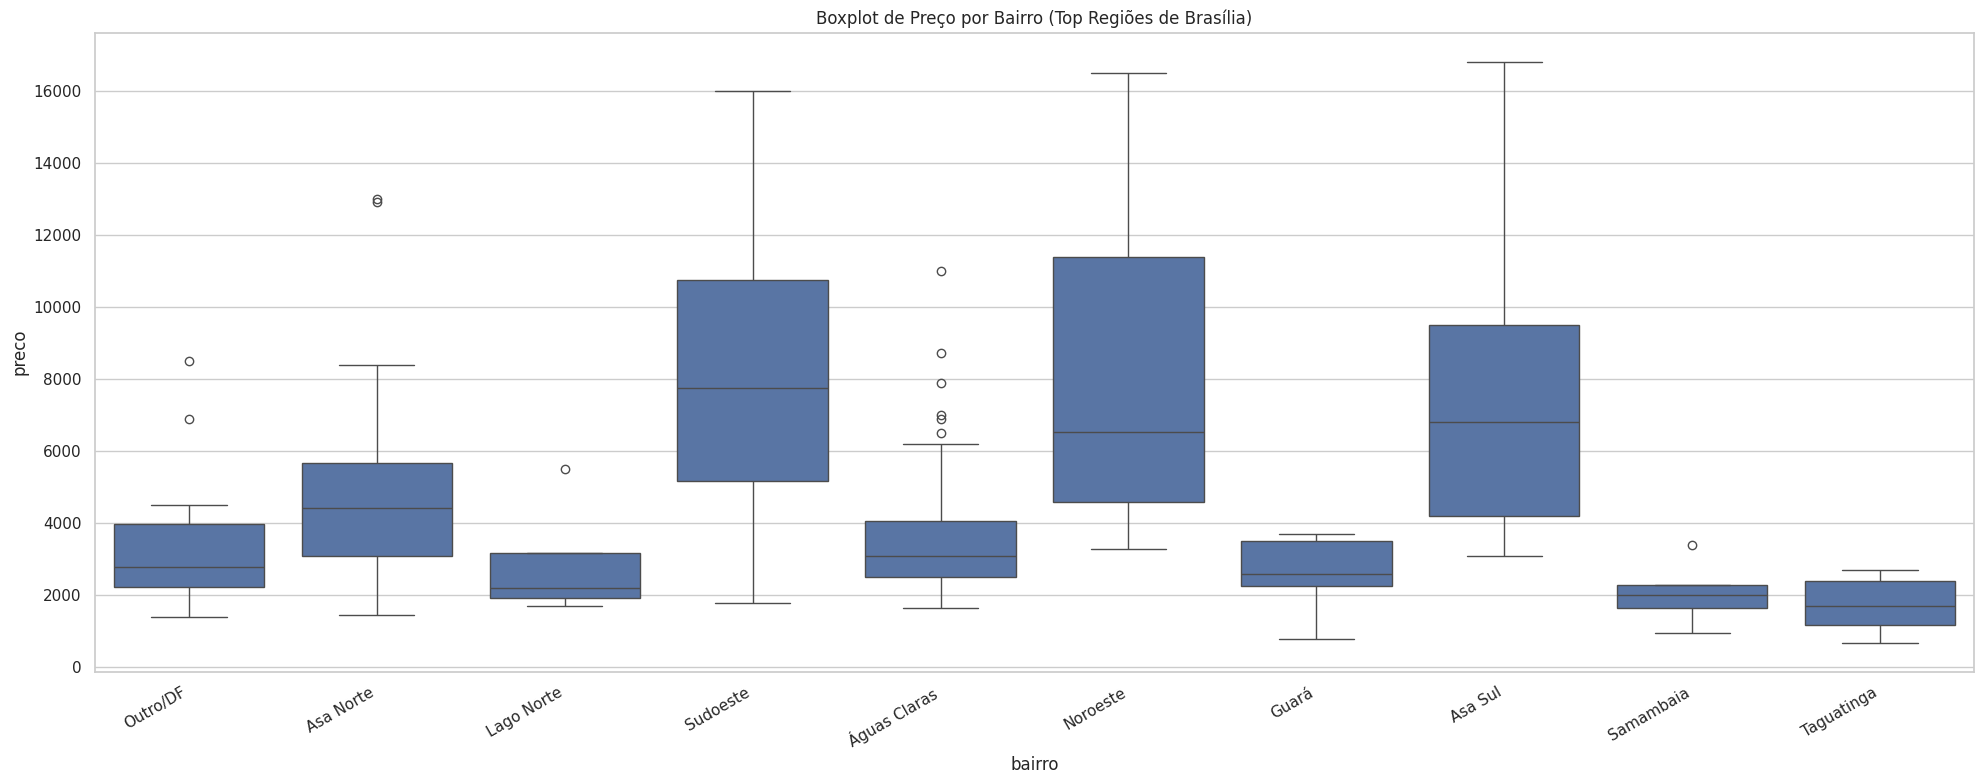

In [24]:
plt.figure(figsize=(20, 12))

# Histograma de preco e preco_m2
plt.subplot(2, 2, 1)
sns.histplot(df_limpo["preco"], kde=True, color="royalblue", bins=20)
plt.title("Distribuição do Preço de Aluguel (R$)")

plt.subplot(2, 2, 2)
sns.histplot(df_limpo["preco_m2"], kde=True, color="forestgreen", bins=20)
plt.title("Distribuição do Preço por m² (R$/m²)")

# Scatter plot: area_m2 vs preco
plt.subplot(2, 2, 3)
sns.regplot(
    data=df_limpo,
    x="area_m2",
    y="preco",
    scatter_kws={'alpha': 0.6, 'color': 'darkblue'},
    line_kws={'color': 'firebrick'}
)
plt.title("Área (m²) x Preço de Aluguel (R$) com Linha de Tendência")

# Matriz de Correlação
plt.subplot(2, 2, 4)
cols_corr = ["preco", "area_m2", "quartos", "vagas", "preco_m2"]
sns.heatmap(df_limpo[cols_corr].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de Correlação Linear")

plt.tight_layout()
plt.show()

# Boxplot de Preço por Bairro
plt.figure(figsize=(20, 8))
top_bairros = df_limpo["bairro"].value_counts().nlargest(10).index
sns.boxplot(data=df_limpo[df_limpo["bairro"].isin(top_bairros)], x="bairro", y="preco")
plt.xticks(rotation=30, ha="right")
plt.title("Boxplot de Preço por Bairro (Top Regiões de Brasília)")
plt.tight_layout()
plt.show()



## Célula 4: Modelagem com Regressão Linear, VIF e Comparação

In [26]:
# Preparação das variáveis preditoras com One-Hot Encoding
features = ["area_m2", "quartos", "vagas", "bairro"]
df_modelo = pd.get_dummies(df_limpo[["preco"] + features], drop_first=True)

X = df_modelo.drop(columns=["preco"])
y = df_modelo["preco"]

# Verificação de Multicolinearidade (VIF)
vif_df = pd.DataFrame()
vif_df["Variável"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X.values.astype(float), i) for i in range(X.shape[1])]
print("=== FATOR DE INFLAÇÃO DA VARIÂNCIA (VIF) ===")
print(vif_df.to_string(index=False))

# Divisão Treino e Teste (75% / 25%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Treinamento dos Modelos
modelos = {
    "Regressão Linear Múltipla": LinearRegression(),
    "Ridge (L2)": Ridge(alpha=1.0),
    "Lasso (L1)": Lasso(alpha=1.0)
}

resultados = []

for nome, mod in modelos.items():
    mod.fit(X_train, y_train)
    preds = mod.predict(X_test)
    resultados.append({
        "Modelo": nome,
        "R²": r2_score(y_test, preds),
        "RMSE": root_mean_squared_error(y_test, preds),
        "MAE": mean_absolute_error(y_test, preds)
    })

# 5. Transformação Logarítmica em preco: log(y)
mod_log = LinearRegression()
mod_log.fit(X_train, np.log(y_train))
preds_log = np.exp(mod_log.predict(X_test))

resultados.append({
    "Modelo": "Linear com log(preço)",
    "R²": r2_score(y_test, preds_log),
    "RMSE": root_mean_squared_error(y_test, preds_log),
    "MAE": mean_absolute_error(y_test, preds_log)
})

# Tabela Comparativa de Métricas
print("\n=== COMPARAÇÃO DE MODELOS ===")
df_metrics = pd.DataFrame(resultados)
print(df_metrics.to_string(index=False))

# Coeficientes do Modelo Linear Múltiplo
coef_df = pd.DataFrame({
    "Variável": X.columns,
    "Impacto Estimado (R$)": modelos["Regressão Linear Múltipla"].coef_
})
print("\n=== COEFICIENTES ESTIMADOS (R$) ===")
print(coef_df.to_string(index=False))

=== FATOR DE INFLAÇÃO DA VARIÂNCIA (VIF) ===
           Variável      VIF
            area_m2 2.406987
            quartos 2.140641
              vagas 1.902283
     bairro_Asa Sul 1.492079
       bairro_Guará 1.247466
  bairro_Lago Norte 1.125563
    bairro_Noroeste 1.780782
    bairro_Outro/DF 1.392361
   bairro_Samambaia 1.158054
    bairro_Sudoeste 1.359554
  bairro_Taguatinga 1.191641
bairro_Águas Claras 2.136003

=== COMPARAÇÃO DE MODELOS ===
                   Modelo       R²        RMSE         MAE
Regressão Linear Múltipla 0.791579 1468.140278  997.389455
               Ridge (L2) 0.778143 1514.725385 1047.251945
               Lasso (L1) 0.790837 1470.750583 1000.635574
    Linear com log(preço) 0.743288 1629.370286  887.508809

=== COEFICIENTES ESTIMADOS (R$) ===
           Variável  Impacto Estimado (R$)
            area_m2              27.212452
            quartos             558.495371
              vagas             755.707000
     bairro_Asa Sul            1042.537391


# RELATÓRIO

### Diagnóstico de Multicolinearidade (VIF)

Ausência de multicolinearidade crítica: Todas as variáveis preditoras obtiveram valores de VIF inferiores a 2,5 (o limiar de alerta na literatura estatística costuma ser VIF > 5 ou 10). Mesmo havendo correlação natural entre tamanho ("area_m2" com VIF de 2,41) e número de cômodos ("quartos" com VIF de 2,14), a informação trazida por cada atributo é suficientemente independente, permitindo estimar os coeficientes de regressão sem instabilidade numérica e sem necessidade de alterar ou eliminar variáveis.

###Comparação e Desempenho dos Modelos

O melhor modelo em $R^2$ e RMSE foi a Regressão Linear Múltipla padrão, que apresentou o melhor ajuste global com $R^2 \approx 0,792$. Portanto, o modelo explica cerca de 79,2% da variabilidade do valor de aluguel nos dados de teste. Além disso, o modelo também apresentou o menor erro quadrático médio ($\text{RMSE} \approx \text{R\$\ } 1.468,14$).

O Lasso ($L_1$) teve desempenho quase idêntico ao modelo clássico com $R^2 \approx 0,791$ e $\text{MAE} \approx \text{R\$\ } 1.000,64$, indicando que nenhuma variável preditora é puramente ruído a ponto de ser zerada pela penalização.

O Ridge ($L_2$) teve leve perda de acurácia com $R^2 \approx 0,778$, o que é esperado quando não há multicolinearidade severa que justifique o encolhimento forçado dos coeficientes.

Quanto à Transformação Logarítmica da variável "preço", embora o $R^2$ tenha caído para 0,743 e o RMSE subido para R$ 1.629,37, o MAE caiu para R$ 887,51, o menor erro médio absoluto de todos.

### Interpretação Econômica dos Coeficientes

Como a categoria de referência do *One-Hot Encoding* é a **Asa Norte**, bairro omitido pelo `drop_first=True`, todos os coeficientes de bairro representam o ganho ou desconto médio em relação a um apartamento idêntico na Asa Norte:

* Área: Cada metro quadrado adicional eleva o preço do aluguel em R$ 27,21/mês, mantendo as demais características constantes.

* Quartos: A adição de um quarto extra aumenta o aluguel estimado em R$ 558,50/mês.

* Vagas de garagem: Cada vaga de garagem disponível agrega R$ 755,71/mês ao aluguel, impacto superior ao de um quarto adicional, destacando a alta valorização de vagas no DF.

* Localização e Bairros vs. Asa Norte de regiões mais valorizadas: Imóveis no Noroeste (+R$ 1.384,02), Asa Sul (+R$ 1.042,54) e Sudoeste (+R$ 330,40) apresentam prêmios médios expressivos em relação à Asa Norte.


* Regiões periféricas e Cidades-satélites: Apresentam deságio acentuado em relação ao Plano Piloto para o mesmo padrão construtivo. Apartamentos equivalentes em Taguatinga (-R$ 2.025,83), Samambaia (-R$ 2.017,23), Guará (-R$ 1.845,05) e Águas Claras (-R$ 1.717,44) têm aluguéis consideravelmente inferiores.

### Limitações e Considerações Éticas

Os valores coletados no Wimoveis são preços contratuais pretendidos e não necessariamente os valores efetivamente fechados após negociação. Ademais, alguns fatores determinantes para apartamentos em Brasília não foram estruturados. Exemplos são: andar, taxa de condomínio inclusa ou não, se o imóvel é mobiliado/reformado ou nascente/poente).

Quanto a aspectos éticos, O scraping foi realizado com atraso entre requisições para evitar sobrecarga no servidor do portal e sem quebra de mecanismos restritivos de dados privados de usuários.